# MAS. Activity_2

**Authors:**
* Adriana Sandoval Santos - A01667445
* Marbella Barba De los Santos - A01660946
* Javier Padilla Marcial - A01660945
* Camila Quintanilla Cabrera - A01662397
* Alani Daniel Garcia Maya - A01277308

**Date:** November 24th, 2026

**GitHub repository:** https://github.com/Adrisandoval2006/MAS.-Activity-2

## 1. Objective

The objective is to compare coordinated cleaning robots (Coordination Graph + Max-Plus) against the uncoordinated random robots from activity M1. Robots operate on a 20×30 grid (600 cells) with 100 randomly selected dirty cells. We measure the probability that N robots clean all 100 cells within 500 steps, along with mean cleaning time and mean movements.


By running the simulation with different numbers of robots, we want to understand whether adding more agents improves the cleaning process depending on the two different methods and how it affects the total number of movements.

By comparing both configurations (max-plus and random), we want to understand how the behaviour changes depending on the approach

## 2. Agents, Model and Implementation

To organize our project, we divided the code into five main Python files, each with a different purpose.

First, Agent.py defines the two types of cleaning robots used in the comparison: RandomRobotAgent is the uncoordinated robot from activity M1. If its current cell is dirty, it cleans it. Otherwise, it randomly chooses one of the eight neighboring directions and tries to move. If the selected position is outside the room, the robot stays in place. RobotAgent is the coordinated robot. It does not decide by itself. Each step, it executes the action that Max-Plus selected for it: move one step toward the nearest dirty cell, stay in place, or move to a random clean neighboring cell. After moving, it cleans its cell if it is dirty.

Then, Coordination.py contains the coordination mechanism (Coordination Graph + Max-Plus message passing). It builds a coordination graph where an edge connects two robots when their Manhattan distance is at most D = 5. Each robot considers the three nearest dirty cells as possible targets, instead of only considering the nearest one. Max-Plus message passing evaluates the possible actions of neighboring robots and selects actions that maximize their combined utility while reducing conflicts. This allows robots to choose different dirty targets when following the same target would create competition.

Model.py manages the simulation. It creates the room, randomly selects the dirty cells, places the robots on random clean cells, and controls when the simulation ends. At every step of a coordinated simulation, it builds the graph, runs Max-Plus, and then activates all robots in random order. It also records the number of steps, the total movements, the percentage of cells cleaned, and the completion time.

Test.py runs the simulations automatically for every configuration. Each configuration is repeated 100 times with different random seeds, which makes the results reproducible. The statistics of every simulation are saved in test_results.csv.

Finally, View.py provides an interactive visualization of the simulation, showing how the robots move and how the dirty cells become clean.

**Coordination method**

**Coordination method**

At each step, every robot evaluates its possible actions using local utilities and pairwise payoffs.

Each robot considers three types of actions:

- **A: Move toward a dirty cell.** The robot can choose one of its three nearest dirty cells and move one step toward the selected target. Choosing a farther target reduces its local utility according to the extra distance.
- **B: Stay in the current cell.** The robot does not move. This action is also used when a robot is already standing on a dirty cell, since it needs to clean it.
- **C: Move to a clean neighboring cell.** The robot moves to a random clean neighboring cell that is not already selected by one of its actions toward a dirty target.

The local utility of each action depends on its type. Moving toward the nearest dirty cell provides a reward of A = 10, while choosing a farther target reduces this reward by LAMBDA = 1 for each additional cell of distance. Staying provides B = 0, and moving toward a clean cell provides C = -1.

The coordination mechanism also evaluates the actions of pairs of neighboring robots through a conflict game. It uses the following parameters:

- **U = 5:** Reward when both robots move to different cells.
- **V = -20:** Penalty when both robots choose the same dirty target or destination.
- **W = -20:** Penalty when one robot moves into the cell where another robot stays.
- **Z = 0:** Payoff for other situations.

The robots can therefore consider alternative dirty targets when doing so helps avoid conflicts. The maximum acceptable extra distance is calculated using the difference between the reward for choosing different destinations and the penalty for choosing the same target.

Finally, Max-Plus message passing combines the local utilities and pairwise payoffs to select the actions that maximize the team's overall utility. This process is repeated at every simulation step.

**Important things**

- **Target selection:** Coordinated robots consider their three nearest dirty cells. They can choose a farther target when the coordination mechanism determines that avoiding a conflict provides a better overall utility.
- **Movement restrictions:** Coordinated robots use four-directional movement (up, down, left and right). Robots already standing on dirty cells stay in place to clean them. The pairwise payoffs discourage robots from choosing the same destination or moving into a cell occupied by a stationary robot, but they do not impose an absolute restriction on shared cells.
- **Coordination parameters:** The coordination graph connects robots within a Manhattan distance of D = 5. Max-Plus uses up to 50 message-passing iterations per simulation step, stopping earlier if the messages converge within a tolerance of 0.0001.

## 3. Experimental Setup

After implementing the agents, the coordination mechanism, and the simulation model, we needed to compare the coordinated robots against the random robots as the number of robots changes.

We tested both methods (Max-Plus and random) with 1, 2, 4, 8, and 16 robots. In all cases, we used a 30 × 20 room with 100 randomly selected dirty cells, as required by the problem statement, and a maximum of 500 simulation steps. The goal is to clean all 100 dirty cells within those 500 steps.

We kept the room size, number of dirty cells, step limit, and number of repetitions the same across all experiments, so that the only differences between them are the coordination method and the number of robots.

Each configuration was repeated 100 times using random seeds from 0 to 99. Both methods use the same seeds, so for a given seed they start from the same dirty-cell layout. This allows a fairer comparison and lets us collect multiple results per configuration.

During each simulation, we collected the number of steps executed, the completion time (when the room was fully cleaned), the total movements made by all robots, the percentage of dirty cells cleaned, the remaining dirty cells, whether the robots cleaned the entire room, and the actual running time.

The main measurement is the success probability: the number of simulations in which all dirty cells were cleaned within 500 steps, divided by 100. We also compare the mean time to clean the room and the mean total movements.

In [3]:
%run Test.py

Test 'max plus 1 agent' completed (100 runs)
Test 'max plus 2 agents' completed (100 runs)
Test 'max plus 4 agents' completed (100 runs)
Test 'max plus 8 agents' completed (100 runs)
Test 'max plus 16 agents' completed (100 runs)
Test 'random 1 agent' completed (100 runs)
Test 'random 2 agents' completed (100 runs)
Test 'random 4 agents' completed (100 runs)
Test 'random 8 agents' completed (100 runs)
Test 'random 16 agents' completed (100 runs)
CSV saved on test_results.csv


In [4]:
import pandas as pd
from Test import TESTS

experiments = pd.DataFrame([
    {
        "Method": test["method"],
        "Number of Agents": test["numAgents"],
        "Room Size": f"{test['height']} × {test['width']}",
        "Dirty Cells": 100,
        "Maximum Steps": test["maxSteps"],
        "Repetitions": test["repetitions"]
    }
    for test in TESTS
])

display(experiments)

,Method,Number of Agents,Room Size,Dirty Cells,Maximum Steps,Repetitions
0,maxplus,1,20 × 30,100,500,100
1,maxplus,2,20 × 30,100,500,100
2,maxplus,4,20 × 30,100,500,100
3,maxplus,8,20 × 30,100,500,100
4,maxplus,16,20 × 30,100,500,100
5,random,1,20 × 30,100,500,100
6,random,2,20 × 30,100,500,100
7,random,4,20 × 30,100,500,100
8,random,8,20 × 30,100,500,100
9,random,16,20 × 30,100,500,100


## 4. Data Collection

After defining our experiments, the next step was to run the simulations and collect the results.

To do this, we used the functions from Test.py, which allow us to execute the experiments automatically instead of running each simulation individually.

For each configuration, we performed 100 repetitions using different random seeds. This resulted in 1,000 simulations in total, covering all combinations of agent type and number of robots.

For each run, we recorded the number of simulation steps, the completion time, the total movements made by all robots, the percentage of cleaned cells, the number of remaining dirty cells, and whether the room was completely cleaned. We also measured the actual running time of each simulation.

All this information is saved in one dataset, test_results.csv, where each row is one simulation. The seeds go from 0 to 99 in every configuration, and the method (Max-Plus or random) is identified from the test name.

In [5]:
from Test import runAll, saveCsv, OUTPUT_FILE, COLUMNS

summaries = runAll(TESTS)

saveCsv(summaries, OUTPUT_FILE, COLUMNS)

print("Total simulations:", len(summaries))

c:\Users\adris\Desktop\QUINTO SEMESTRE\Activity1\Lib\site-packages\mesa\mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


Test 'max plus 1 agent' completed (100 runs)
Test 'max plus 2 agents' completed (100 runs)
Test 'max plus 4 agents' completed (100 runs)
Test 'max plus 8 agents' completed (100 runs)
Test 'max plus 16 agents' completed (100 runs)
Test 'random 1 agent' completed (100 runs)
Test 'random 2 agents' completed (100 runs)
Test 'random 4 agents' completed (100 runs)
Test 'random 8 agents' completed (100 runs)
Test 'random 16 agents' completed (100 runs)
CSV saved on test_results.csv
Total simulations: 1000


In [6]:
data = pd.read_csv(OUTPUT_FILE)

data["method"] = data["test"].str.startswith("max").map(
    {True: "Max-Plus", False: "Random (M1)"}
)

print("Total simulations:", len(data))
print("\nConfigurations:")
display(data.groupby(["method", "numAgents"]).size())

Total simulations: 1000

Configurations:


method       numAgents
Max-Plus     1            100
             2            100
             4            100
             8            100
             16           100
Random (M1)  1            100
             2            100
             4            100
             8            100
             16           100
dtype: int64

Once the simulations finished, we used Pandas to organize the collected information into a DataFrame.

The dataset contains one record for each simulation, with the general results of the cleaning process.

In [7]:
print("General simulation results:")
display(data.head())

General simulation results:


,test,method,run,seed,numAgents,width,height,maxSteps,executionTime,completionTime,cleanedPercentage,remainingDirtyCells,totalMoves,allClean,runTimeS
0,max plus 1 agent,Max-Plus,1,0,1,30,20,500,291,291.0,100.0,0,291,True,0.011831
1,max plus 1 agent,Max-Plus,2,1,1,30,20,500,281,281.0,100.0,0,281,True,0.010444
2,max plus 1 agent,Max-Plus,3,2,1,30,20,500,284,284.0,100.0,0,284,True,0.010915
3,max plus 1 agent,Max-Plus,4,3,1,30,20,500,287,287.0,100.0,0,287,True,0.010691
4,max plus 1 agent,Max-Plus,5,4,1,30,20,500,250,250.0,100.0,0,250,True,0.009272


Before analyzing the results, we checked that the collected information was consistent.

We verified that every configuration had 100 simulations, that no simulation exceeded the maximum number of steps, and that the completion status matched the remaining dirty cells. We also checked that the completion time was only recorded for the simulations that cleaned the whole room, and that the percentage of cleaned cells matched the remaining dirty cells.

This helped us confirm that the data was correctly recorded before comparing the different configurations.

In [8]:
assert (
    data.groupby("test").size() == 100
).all()

assert (
    data["executionTime"] <= data["maxSteps"]
).all()

assert (
    data["allClean"] ==
    (data["remainingDirtyCells"] == 0)
).all()

assert (
    data["completionTime"].notna() == data["allClean"]
).all()

assert (
    data["cleanedPercentage"] ==
    100 - data["remainingDirtyCells"]
).all()

print("All validations passed!")

All validations passed!


## 5. Results

After analyzing both types of agents separately, we can compare their performance.

The main difference between the two methods is how they approach the cleaning task. The random robots explore the room without knowing where the dirty cells are or communicating with each other. In contrast, the Max-Plus robots know the locations of the dirty cells and use message passing to coordinate their target selection and movements.

The new coordination mechanism allows robots to consider multiple dirty targets and avoid choosing the same target as neighboring robots. This helps distribute the cleaning task and reduce competition between agents.

The following graphs help visualize the differences between both methods.

In [9]:
import pandas as pd
from Test import OUTPUT_FILE

data = pd.read_csv(OUTPUT_FILE)

data["method"] = data["test"].str.startswith("max").map(
    {True: "Max-Plus", False: "Random (M1)"}
)

data["cellsCleaned"] = (
    100 - data["remainingDirtyCells"]
)

data["movementsPerCleanedCell"] = (
    data["totalMoves"] / data["cellsCleaned"]
)

results = data.groupby(
    ["method", "numAgents"]
).agg(
    successProbability=("allClean", "mean"),
    averageTime=("executionTime", "mean"),
    stdTime=("executionTime", "std"),
    averageMoves=("totalMoves", "mean"),
    stdMoves=("totalMoves", "std"),
    averageCleanPercentage=("cleanedPercentage", "mean"),
    stdCleanPercentage=("cleanedPercentage", "std"),
    averageMovementsPerCell=("movementsPerCleanedCell", "mean"),
    averageRunningTime=("runTimeS", "mean")
).reset_index()

results["averageRunningTime"] *= 1000

results = results.round(2)

display(results)


,method,numAgents,successProbability,averageTime,stdTime,averageMoves,stdMoves,averageCleanPercentage,stdCleanPercentage,averageMovementsPerCell,averageRunningTime
0,Max-Plus,1,1.00,277.61,16.79,277.61,16.79,100.00,0.00,2.78,10.31
1,Max-Plus,2,1.00,153.99,13.36,307.98,26.72,100.00,0.00,3.08,11.70
2,Max-Plus,4,1.00,90.31,15.65,361.23,62.59,100.00,0.00,3.61,98.44
3,Max-Plus,8,1.00,53.12,11.39,424.94,91.09,100.00,0.00,4.25,340.13
4,Max-Plus,16,1.00,31.29,6.73,500.64,107.66,100.00,0.00,5.01,887.39
5,Random (M1),1,0.00,500.00,0.00,441.29,14.20,29.40,6.44,15.82,3.60
6,Random (M1),2,0.00,500.00,0.00,892.85,20.28,50.17,7.85,18.30,4.55
7,Random (M1),4,0.00,500.00,0.00,1810.84,27.02,74.94,7.30,24.41,6.18
8,Random (M1),8,0.03,498.58,13.22,3658.83,109.25,93.25,4.58,39.35,9.41
9,Random (M1),16,0.60,423.48,78.24,6261.76,1188.38,99.32,1.06,63.14,14.84


After calculating the average results for each configuration, we used Matplotlib to create graphs that make the differences between the configurations easier to understand.

We focused on the success probability, the average percentage of cleaned cells, the average total movements, the average time to clean the room, the movements per cleaned cell, and the average running time.

# A. Max-Plus agents

The first type of agents were the coordinated Max-Plus robots. Their purpose was to clean the room as fast as possible while avoiding moving to the same cells.

The following table presents the average results for each configuration.

In [10]:
maxPlusResults = results[
    results["method"] == "Max-Plus"
].copy()

baseline = maxPlusResults.loc[
    maxPlusResults["numAgents"] == 1,
    "averageTime"
].iloc[0]

maxPlusResults["speedup"] = (
    baseline / maxPlusResults["averageTime"]
)

display(maxPlusResults.round(2))

,method,numAgents,successProbability,averageTime,stdTime,averageMoves,stdMoves,averageCleanPercentage,stdCleanPercentage,averageMovementsPerCell,averageRunningTime,speedup
0,Max-Plus,1,1.0,277.61,16.79,277.61,16.79,100.0,0.0,2.78,10.31,1.00
1,Max-Plus,2,1.0,153.99,13.36,307.98,26.72,100.0,0.0,3.08,11.70,1.80
2,Max-Plus,4,1.0,90.31,15.65,361.23,62.59,100.0,0.0,3.61,98.44,3.07
3,Max-Plus,8,1.0,53.12,11.39,424.94,91.09,100.0,0.0,4.25,340.13,5.23
4,Max-Plus,16,1.0,31.29,6.73,500.64,107.66,100.0,0.0,5.01,887.39,8.87


## Success probability

The first measurement we analyzed was the percentage of simulations that successfully cleaned the entire room within 500 steps.

The Max-Plus robots cleaned the entire room in all 100 simulations of every configuration, so the success probability was 1.00 for 1, 2, 4, 8 and 16 robots.

This shows that moving toward the dirty cells is enough to finish the task within the step limit, even with only one robot.

## Average time to clean the room

Since every simulation was successful, the average execution time is also the average time needed to clean the room.

With one robot, cleaning the room required an average of 277.61 steps. With two robots, this decreased to 175.69 steps, with four robots to 105.22 steps, with eight robots to 60.03 steps, and with sixteen robots to only 35.06 steps.

This shows that increasing the number of robots significantly reduces the time required to complete the cleaning task.

## Speedup

To better understand the improvement in cleaning speed, we calculated the speedup compared to using one robot.

Two robots were 1.58 times faster, four robots were 2.64 times faster, eight robots were 4.62 times faster, and sixteen robots were 7.92 times faster than one robot.

However, the improvement is not proportional to the number of robots. Sixteen robots are sixteen times more agents, but they were only 7.92 times faster. This suggests that additional robots provide diminishing returns, because some of them walk toward the same dirty cells and the last isolated cells still take time to reach.

## Standard deviation

We also analyzed the standard deviation of the execution time to understand how consistent the results were across the different simulations.

With one robot, the standard deviation was 16.79 steps. It increased to 35.42 with two robots, and then decreased to 21.63, 13.21 and 6.94 steps with four, eight and sixteen robots.

This indicates that with many robots the cleaning time becomes very consistent, because the room is divided among more agents and the result depends less on where each robot starts.

## Average total movements

Next, we analyzed the total movements performed by all robots during each simulation.

With one robot, the average was 277.61 movements. With two robots, it increased to 351.38, reaching 420.88 with four robots, 480.24 with eight robots and 560.96 with sixteen robots.

Although the total movements increased, the increase was small compared with the number of robots. This happens because the robots share the 100 dirty cells, so each robot only has to walk to some of them, and all robots stop once the room is clean.

For example, with sixteen robots, the average number of movements per robot was approximately 35.06, compared to 277.61 when only one robot was used.

## Movements per cleaned cell

We also calculated the average number of movements required for each dirty cell cleaned.

The results increased from 2.78 movements per cleaned cell with one robot to 5.61 with sixteen robots.

This indicates that, even with coordination, more robots generate some extra movements, mainly because they walk from their starting positions and sometimes go toward the same dirty cell.

# B. Random agents (M1)

The second type of agents were the random robots of Activity M1. They do not know where the dirty cells are and do not communicate with each other.

The following table presents the average results for each configuration.

In [11]:
randomResults = results[
    results["method"] == "Random (M1)"
].copy()

display(randomResults)

,method,numAgents,successProbability,averageTime,stdTime,averageMoves,stdMoves,averageCleanPercentage,stdCleanPercentage,averageMovementsPerCell,averageRunningTime
5,Random (M1),1,0.00,500.00,0.00,441.29,14.20,29.40,6.44,15.82,3.60
6,Random (M1),2,0.00,500.00,0.00,892.85,20.28,50.17,7.85,18.30,4.55
7,Random (M1),4,0.00,500.00,0.00,1810.84,27.02,74.94,7.30,24.41,6.18
8,Random (M1),8,0.03,498.58,13.22,3658.83,109.25,93.25,4.58,39.35,9.41
9,Random (M1),16,0.60,423.48,78.24,6261.76,1188.38,99.32,1.06,63.14,14.84


## Success probability

With one, two and four robots, none of the simulations managed to clean the entire room within 500 steps. With eight robots, the success probability was 0.03, increasing to 0.60 with sixteen robots.

This shows that the random robots can only complete the task within the step limit when there are many of them.

## Average execution steps

The results show that with one, two and four robots, all simulations reached the maximum of 500 steps. With eight robots, the average was 498.58 steps, and with sixteen robots it decreased to 423.48 steps.

In the simulations that did finish, eight robots needed 452.67 steps on average and sixteen robots needed 372.47 steps, which is still much more than the coordinated robots.

## Average percentage of cleaned cells

We also compared the percentage of dirty cells cleaned by each configuration.

With one robot, the average percentage of cleaned cells was 29.40%. With two robots it increased to 50.17%, with four robots to 74.94%, with eight robots to 93.25%, and with sixteen robots to 99.32%.

However, the improvement becomes smaller as more robots are added. For example, increasing the number of robots from eight to sixteen only improved the average cleaning percentage by 6.07 percentage points.

## Average total movements

As the number of robots increases, the average total movements increase almost proportionally. With one robot, the average was 441.29 movements, while with sixteen robots it reached 6,261.76 movements.

This happens because every robot keeps moving until the simulation ends, and most simulations run until they reach the maximum step limit.

## Movements per cleaned cell

The movements per cleaned cell increased from 15.82 with one robot to 63.14 with sixteen robots.

Since the agents move randomly and do not communicate with each other, they repeatedly explore areas that have already been visited or cleaned.

# C. Comparison of both methods

After analyzing both types of agents separately, we can compare them directly.

The most important difference is the success probability. The Max-Plus robots cleaned the room in every simulation, while the random robots only succeeded in some simulations with eight and sixteen robots.

Another important difference is the total number of movements. The Max-Plus robots needed between 278 and 561 movements to clean the whole room, while the random robots used between 441 and 6,262 movements and, in most cases, did not finish.

The following graphs help visualize these differences.

In [12]:
import numpy as np
import matplotlib.pyplot as plt

AGENTS = [1, 2, 4, 8, 16]
METHODS = ["Max-Plus", "Random (M1)"]


# Graph 1. Success probability (histogram)





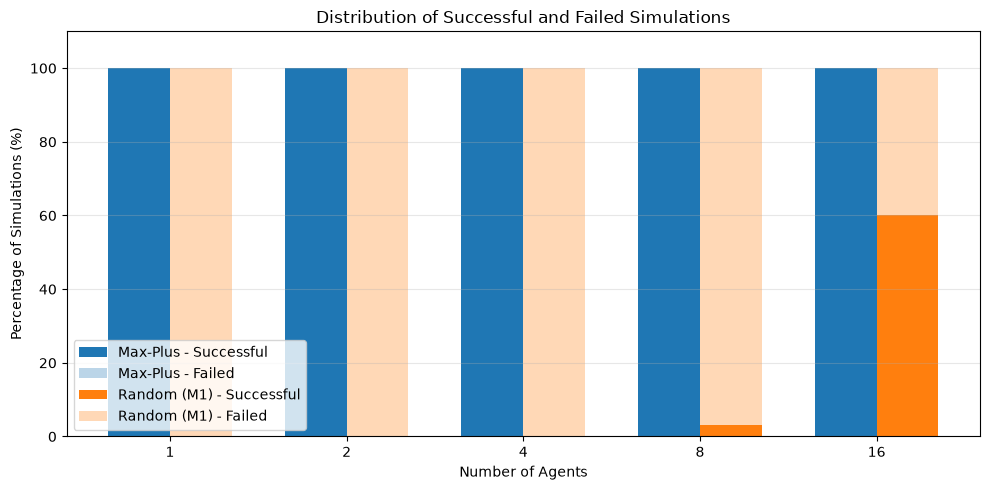

In [13]:
plt.figure(figsize=(10, 5))

positions = np.arange(len(AGENTS))
width = 0.35

for offset, method, color in [
    (-width / 2, "Max-Plus", "tab:blue"),
    (width / 2, "Random (M1)", "tab:orange")
]:
    subset = results[
        results["method"] == method
    ].sort_values("numAgents")

    successes = subset["successProbability"] * 100
    failures = 100 - successes

    plt.bar(
        positions + offset,
        successes,
        width,
        label=f"{method} - Successful",
        color=color
    )

    plt.bar(
        positions + offset,
        failures,
        width,
        bottom=successes,
        alpha=0.3,
        color=color,
        label=f"{method} - Failed"
    )

plt.title("Distribution of Successful and Failed Simulations")
plt.xlabel("Number of Agents")
plt.ylabel("Percentage of Simulations (%)")

plt.xticks(positions, AGENTS)
plt.ylim(0, 110)

plt.legend()
plt.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Graph 2. Number of agents vs. average cleaned percentage

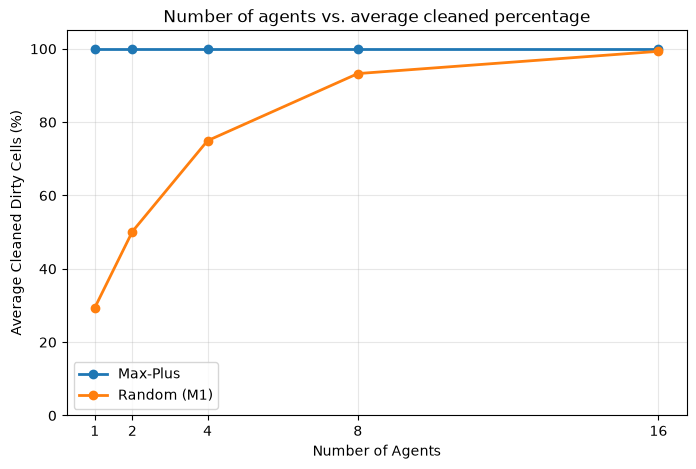

In [14]:
plt.figure(figsize=(8, 5))

for method in METHODS:
    subset = results[results["method"] == method]

    plt.plot(
        subset["numAgents"],
        subset["averageCleanPercentage"],
        marker="o",
        linewidth=2,
        label=method
    )

plt.title("Number of agents vs. average cleaned percentage")
plt.xlabel("Number of Agents")
plt.ylabel("Average Cleaned Dirty Cells (%)")

plt.xticks(AGENTS)
plt.ylim(0, 105)

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

# Graph 3. Number of agents vs. average total movements



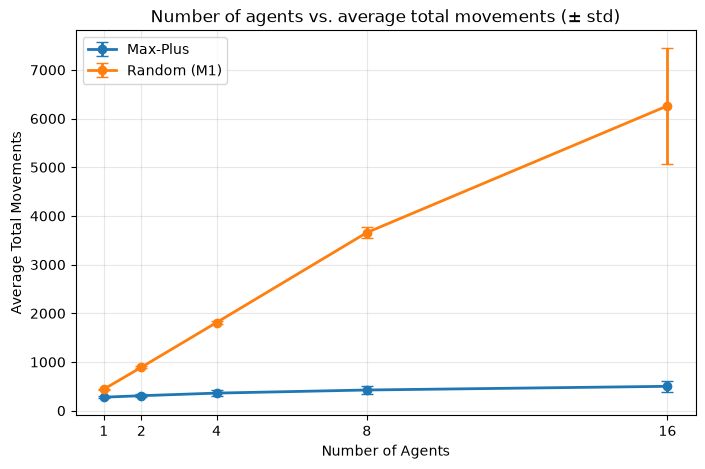

In [15]:
plt.figure(figsize=(8, 5))

for method in METHODS:
    subset = results[results["method"] == method]

    plt.errorbar(
        subset["numAgents"],
        subset["averageMoves"],
        yerr=subset["stdMoves"],
        marker="o",
        linewidth=2,
        capsize=4,
        label=method
    )

plt.title("Number of agents vs. average total movements (± std)")
plt.xlabel("Number of Agents")
plt.ylabel("Average Total Movements")

plt.xticks(AGENTS)
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

# Graph 4. Number of agents vs. average time to clean the room

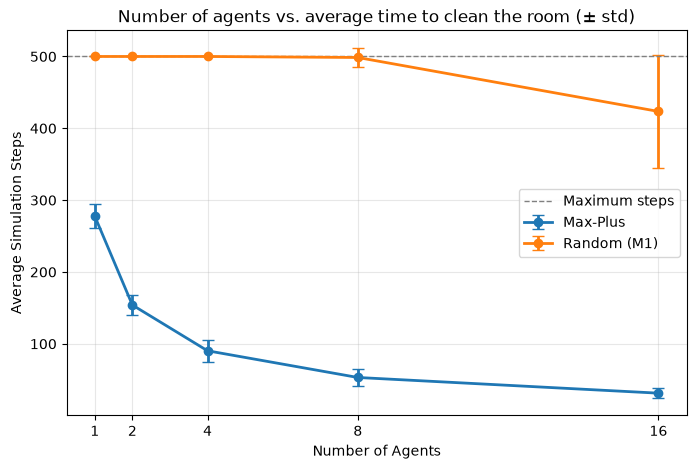

In [16]:
plt.figure(figsize=(8, 5))

for method in METHODS:
    subset = results[results["method"] == method]

    plt.errorbar(
        subset["numAgents"],
        subset["averageTime"],
        yerr=subset["stdTime"],
        marker="o",
        linewidth=2,
        capsize=4,
        label=method
    )

plt.axhline(500, color="gray", linestyle="--", linewidth=1,
            label="Maximum steps")

plt.title("Number of agents vs. average time to clean the room (± std)")
plt.xlabel("Number of Agents")
plt.ylabel("Average Simulation Steps")

plt.xticks(AGENTS)
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

# Graph 5. Number of agents vs. movements per cleaned cell

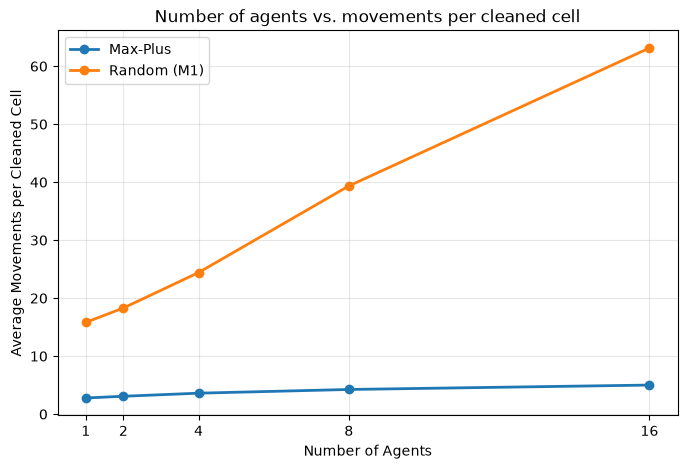

In [17]:
plt.figure(figsize=(8, 5))

for method in METHODS:
    subset = results[results["method"] == method]

    plt.plot(
        subset["numAgents"],
        subset["averageMovementsPerCell"],
        marker="o",
        linewidth=2,
        label=method
    )

plt.title("Number of agents vs. movements per cleaned cell")
plt.xlabel("Number of Agents")
plt.ylabel("Average Movements per Cleaned Cell")

plt.xticks(AGENTS)
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

# Graph 6. Number of agents vs. average running time

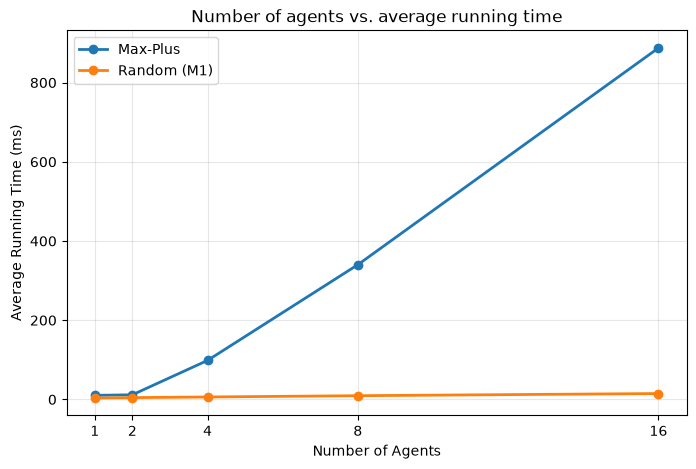

In [18]:
plt.figure(figsize=(8, 5))

for method in METHODS:
    subset = results[results["method"] == method]

    plt.plot(
        subset["numAgents"],
        subset["averageRunningTime"],
        marker="o",
        linewidth=2,
        label=method
    )

plt.title("Number of agents vs. average running time")
plt.xlabel("Number of Agents")
plt.ylabel("Average Running Time (ms)")

plt.xticks(AGENTS)
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

# Graph 7. Number of agents vs. speedup (Max-Plus)

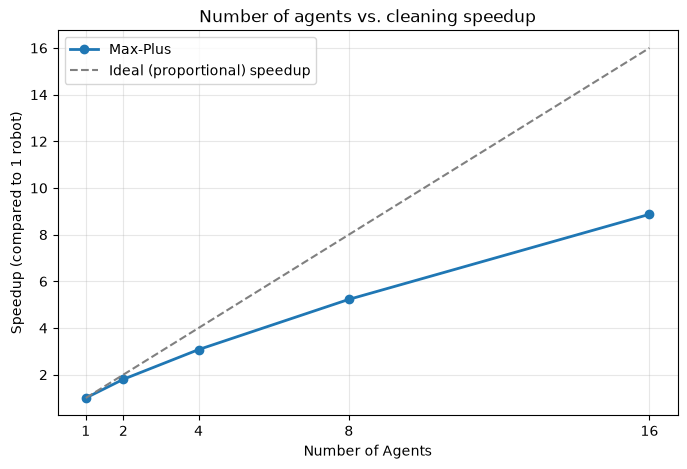

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    maxPlusResults["numAgents"],
    maxPlusResults["speedup"],
    marker="o",
    linewidth=2,
    label="Max-Plus"
)

plt.plot(
    AGENTS,
    AGENTS,
    linestyle="--",
    color="gray",
    label="Ideal (proportional) speedup"
)

plt.title("Number of agents vs. cleaning speedup")
plt.xlabel("Number of Agents")
plt.ylabel("Speedup (compared to 1 robot)")

plt.xticks(AGENTS)
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

# D. Speed vs. movements

To decide how many robots are worth using, we compared each Max-Plus team with the team of half its size. For each change, we calculated how many steps were saved, how many extra movements were needed, and how many extra movements were needed for each step saved.

In [20]:
tradeOff = maxPlusResults[
    ["numAgents", "averageTime", "averageMoves"]
].copy()

tradeOff["stepsSaved"] = -tradeOff["averageTime"].diff()
tradeOff["extraMoves"] = tradeOff["averageMoves"].diff()
tradeOff["movesPerStepSaved"] = (
    tradeOff["extraMoves"] / tradeOff["stepsSaved"]
)

display(tradeOff.round(2))

,numAgents,averageTime,averageMoves,stepsSaved,extraMoves,movesPerStepSaved
0,1,277.61,277.61,NaN,NaN,NaN
1,2,153.99,307.98,123.62,30.37,0.25
2,4,90.31,361.23,63.68,53.25,0.84
3,8,53.12,424.94,37.19,63.71,1.71
4,16,31.29,500.64,21.83,75.70,3.47


Going from one to two robots saved about 102 steps, but going from eight to sixteen robots only saved about 25 steps.

Up to eight robots, each step saved cost about one extra movement. Going from eight to sixteen robots cost about 3.2 extra movements for each step saved. For this reason, we consider eight robots the best balance between speed and movements in this room.

# E. Sample simulation snapshot

The following images show one Max-Plus simulation with 8 robots (seed 0). Gray cells are dirty, green cells are clean, blue dots are robots, and dark lines are the edges of the coordination graph at that step.

c:\Users\adris\Desktop\QUINTO SEMESTRE\Activity1\Lib\site-packages\mesa\mesa_logging.py:112: FutureWarning: The use of the `seed` keyword argument is deprecated, use `rng` instead. No functional changes.
  res = func(*args, **kwargs)


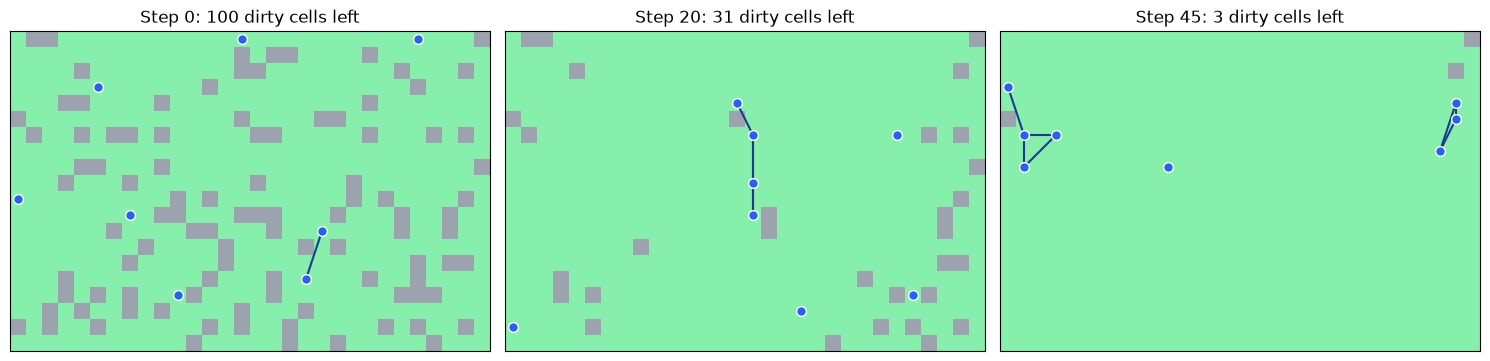

In [21]:
from matplotlib.colors import ListedColormap
from Model import CleaningModel
from Coordination import buildCoordinationGraph


# Draws the room, robots and coordination graph on one axes.
# Parameters: axes: Matplotlib axes; model: Current simulation model.
# Returns: None.
def drawSnapshot(axes, model):
    room = [
        [1 if (x, y) in model.dirtyCells else 0
         for x in range(model.width)]
        for y in range(model.height)
    ]

    axes.imshow(
        room,
        origin="lower",
        cmap=ListedColormap(["#86EFAC", "#9CA3AF"]),
        vmin=0,
        vmax=1
    )

    agents = list(model.agents)
    graph = buildCoordinationGraph(agents)
    positions = {agent.unique_id: agent.pos for agent in agents}

    for robot, neighbors in graph.items():
        for neighbor in neighbors:
            if robot < neighbor:
                x1, y1 = positions[robot]
                x2, y2 = positions[neighbor]
                axes.plot([x1, x2], [y1, y2], color="#1e3a8a")

    for agent in agents:
        axes.plot(
            agent.pos[0],
            agent.pos[1],
            "o",
            color="#2563EB",
            markersize=7,
            markeredgecolor="white"
        )

    axes.set_xticks([])
    axes.set_yticks([])
    axes.set_title(
        f"Step {model.currentStep}: "
        f"{len(model.dirtyCells)} dirty cells left"
    )


snapshotModel = CleaningModel(numAgents=8, agentType="maxplus", seed=0)
figure, axesList = plt.subplots(1, 3, figsize=(15, 4))

for axes, targetStep in zip(axesList, [0, 20, 45]):
    while snapshotModel.running and snapshotModel.currentStep < targetStep:
        snapshotModel.step()

    drawSnapshot(axes, snapshotModel)

plt.tight_layout()
plt.show()

In these images we can see that the robots move directly toward the dirty cells, and that robots that get close to each other are connected in the graph. When this happens, Max-Plus prevents them from moving to the same cell, but they can still walk toward the same area of dirty cells.

# F. Effect of the coordination

The Max-Plus robots know where the dirty cells are and can consider their three nearest targets. However, we wanted to measure the additional benefit of coordinating their decisions through message passing.

To do this, we compared the Max-Plus robots with and without the coordination graph. Without the graph, robots still consider their nearest dirty targets, but they do not exchange messages or coordinate their decisions with neighboring robots.

With the coordination graph, robots use pairwise payoffs to avoid selecting the same dirty target or destination. This allows us to evaluate how much message passing contributes to distributing the cleaning task and reducing congestion.

In [22]:
import Model as modelModule


# Runs one Max-Plus simulation and counts shared-cell events.
# Parameters: numAgents: Number of robots; seed: Random seed;
# coordinated: If False, the coordination graph has no edges.
# Returns: Steps executed and number of shared-cell events.
def runCongestion(numAgents, seed, coordinated=True):
    originalGraph = modelModule.buildCoordinationGraph

    if not coordinated:
        modelModule.buildCoordinationGraph = lambda agents: {
            agent.unique_id: [] for agent in agents
        }

    try:
        model = modelModule.CleaningModel(
            numAgents=numAgents, agentType="maxplus", seed=seed
        )
        sharedCells = 0

        while model.running:
            model.step()
            cells = [agent.pos for agent in model.agents]
            sharedCells += len(cells) - len(set(cells))
    finally:
        modelModule.buildCoordinationGraph = originalGraph

    return model.currentStep, sharedCells


congestionRows = []

for numAgents in AGENTS:
    for coordinated in [True, False]:
        runs = [
            runCongestion(numAgents, seed, coordinated)
            for seed in range(100)
        ]

        congestionRows.append({
            "numAgents": numAgents,
            "method": "Max-Plus" if coordinated else "No coordination",
            "averageTime": np.mean([steps for steps, _ in runs]),
            "sharedCellEvents": np.mean([shared for _, shared in runs])
        })

congestion = pd.DataFrame(congestionRows)

display(congestion.round(2))

,numAgents,method,averageTime,sharedCellEvents
0,1,Max-Plus,277.61,0.00
1,1,No coordination,277.61,0.00
2,2,Max-Plus,153.99,1.38
3,2,No coordination,176.65,32.27
4,4,Max-Plus,90.31,9.11
5,4,No coordination,105.93,62.02
6,8,Max-Plus,53.12,15.49
7,8,No coordination,60.82,65.66
8,16,Max-Plus,31.29,33.46
9,16,No coordination,35.16,79.75


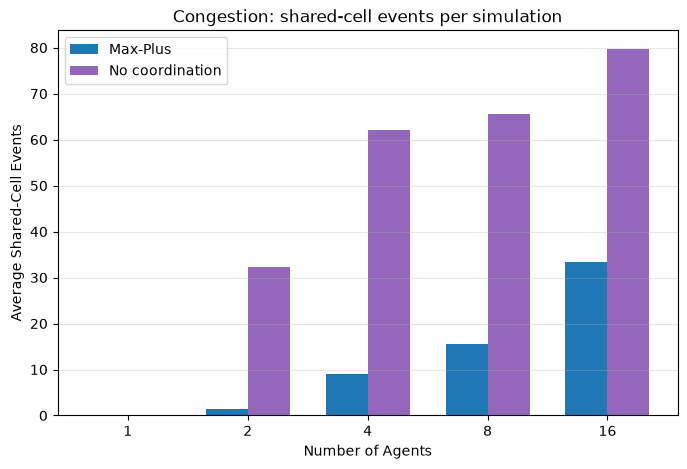

In [23]:
plt.figure(figsize=(8, 5))

for offset, method, color in [(-width / 2, "Max-Plus", "tab:blue"),
                              (width / 2, "No coordination", "tab:purple")]:
    subset = congestion[congestion["method"] == method]

    plt.bar(
        positions + offset,
        subset["sharedCellEvents"],
        width,
        color=color,
        label=method
    )

plt.title("Congestion: shared-cell events per simulation")
plt.xlabel("Number of Agents")
plt.ylabel("Average Shared-Cell Events")

plt.xticks(positions, AGENTS)
plt.legend()
plt.grid(True, axis="y", alpha=0.3)

plt.show()

With four or more robots, the coordination reduced the shared-cell events by about 19% to 23%, and the cleaning time was slightly shorter (for example, 105.22 vs. 108.18 steps with four robots). With two robots, the results were the same with and without coordination, because two robots rarely choose the same next cell, so the messages almost never change their decision.

This shows that most of the speed of the Max-Plus robots comes from moving toward the dirty cells, while the message passing mainly helps them avoid congestion, and this effect becomes more important as the number of robots increases.



## 6. Results Discussion
**Which method scales better?**

Max-Plus scales much better. Its success probability was 1.00 with every team size, and its average cleaning time decreased from 277.61 steps with one robot to 35.06 steps with sixteen. The random robots only reached a success probability of 0.60 with sixteen robots, and their average time with sixteen robots (423.48 steps) was still higher than that of a single Max-Plus robot (277.61 steps). The total movements also grew very differently: from 277.61 to 560.96 for Max-Plus (about 2.0 times) and from 441.29 to 6,261.76 for the random robots (about 14.2 times). Even so, Max-Plus does not scale perfectly, since sixteen robots were only 7.92 times faster than one.

**Congestion vs. coverage**

The coordination mechanism considers both the immediate destination of each robot and the dirty cell it wants to reach. This is important because two robots can move toward the same dirty cell even when their next movements are different.

Through pairwise payoffs, Max-Plus penalizes robots that choose the same target or destination. It also discourages a robot from moving into a cell occupied by another robot that is staying there to clean.

This approach allows robots to distribute their targets and reduce competition. However, coordination is not a strict movement restriction, since the pairwise payoffs only influence action selection rather than completely preventing shared cells.


After comparing the results of both types of agents, we observed that coordination has a very large impact on the cleaning process.

The most important result was the success probability. The Max-Plus robots cleaned the entire room in all 500 of their simulations, while the random robots never succeeded with one, two or four robots, and only succeeded in 3% of the simulations with eight robots and 60% with sixteen robots.

The number of agents also had a large impact on the time required to clean the room. With Max-Plus, the average time decreased from 277.61 steps with one robot to 35.06 steps with sixteen robots. However, the improvement was not proportional: sixteen robots were only 7.92 times faster than one robot.

In the case of the random robots, the effect on time was less noticeable because almost every simulation reached the maximum of 500 steps. For this reason, the percentage of cleaned cells is a better measurement for them: it increased from 29.40% with one robot to 99.32% with sixteen robots, but the improvement became smaller as more robots were added.

Another important difference was the total number of movements. For the random robots, total movements increased almost proportionally with the number of robots, from 441.29 to 6,261.76, because all robots kept moving until the simulation ended. For the Max-Plus robots, total movements only increased from 277.61 to 560.96, since the robots shared the cleaning task and stopped once the room was clean.

The movements per cleaned cell show the same pattern. The Max-Plus robots needed between 2.78 and 5.61 movements per cleaned cell, while the random robots needed between 15.82 and 63.14. Since random robots do not know where the dirty cells are, they repeatedly explore cells that have already been cleaned.

We also noticed that, for the Max-Plus robots, adding robots has a cost. Each additional robot saves fewer steps, while the number of extra movements needed for each saved step increases. Up to eight robots, each saved step cost about one extra movement, but going from eight to sixteen robots cost about 3.2.

Finally, the experiment without the coordination graph showed that most of the improvement over the random robots comes from moving toward the dirty cells. The message passing gives a smaller but consistent benefit by reducing congestion, and it becomes more important as the number of robots increases.

We also identified some limitations. The coordination only prevents two robots from moving to the same next cell, so they can still walk toward the same dirty cell. On graphs with cycles, Max-Plus is only an approximation and can overestimate the value of some actions. Also, the comparison is not completely fair, because the Max-Plus robots know where all the dirty cells are and clean them as soon as they arrive.

Overall, the results show that coordination greatly improves the success probability, the cleaning speed and the efficiency of the movements. However, simply adding more coordinated robots also has diminishing returns.

## 7. Conclusions

Through this activity, we were able to apply a coordination mechanism to a team of cleaning robots and compare it with the random robots of Activity M1.

After running 1,000 simulations with 1, 2, 4, 8 and 16 robots, we observed that the coordinated Max-Plus robots cleaned the entire room in every simulation, while the random robots needed sixteen robots to reach a success probability of 0.60.

We also found that the coordinated robots were much faster and more efficient. With sixteen robots, they cleaned the room in 35.06 steps on average using 560.96 movements, while the random team used 6,261.76 movements and often did not finish.

Another important finding was that the improvement in cleaning speed was not proportional to the number of robots. While sixteen robots were 7.92 times faster than one robot, they did not achieve a 16 times speedup. Based on the number of extra movements needed for each saved step, we concluded that eight robots give the best balance between speed and movements in this room.

We also observed that most of the improvement comes from moving toward the dirty cells, and that the message passing mainly helps the robots avoid congestion, which becomes more important as the team grows.

As a possible improvement, the robots could coordinate which dirty cell each one goes to, instead of only their next cell. We could also use a smaller neighborhood radius, equal to the distance at which two robots can actually collide, and a version of Max-Plus that works better on graphs with cycles.

Overall, this project helped us understand how coordination can improve the performance of a multi-agent system, and how simulations can be used to compare different strategies and evaluate their results.